# Sales Prediction Using Python
**Track:** Data Science | Oasis Infobyte SIP

**Objective:** Predict product sales from advertising spend on TV, Radio and
Newspaper, and find which channel has the greatest impact on sales.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [18]:
# The first column is just a row number, so use it as the index
df = pd.read_csv("Advertising Budget and Sales.csv", index_col=0)

# Shorter column names
df.columns = ["TV", "Radio", "Newspaper", "Sales"]
df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [19]:
print("Shape:", df.shape)
df.info()

Shape: (200, 4)
<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB


In [20]:
print("Null values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Null values per column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [21]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


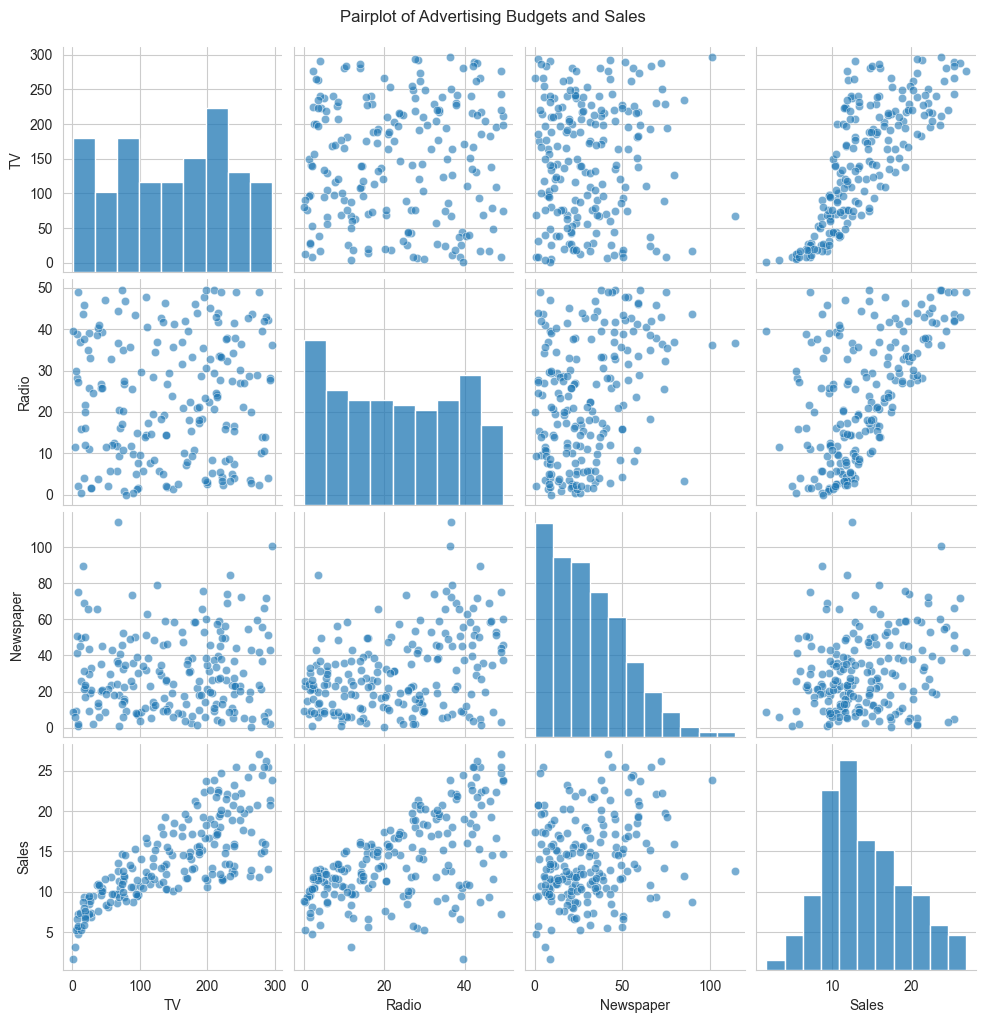

In [22]:
sns.pairplot(df, diag_kind="hist", plot_kws={"alpha": 0.6})
plt.suptitle("Pairplot of Advertising Budgets and Sales", y=1.02)
plt.show()

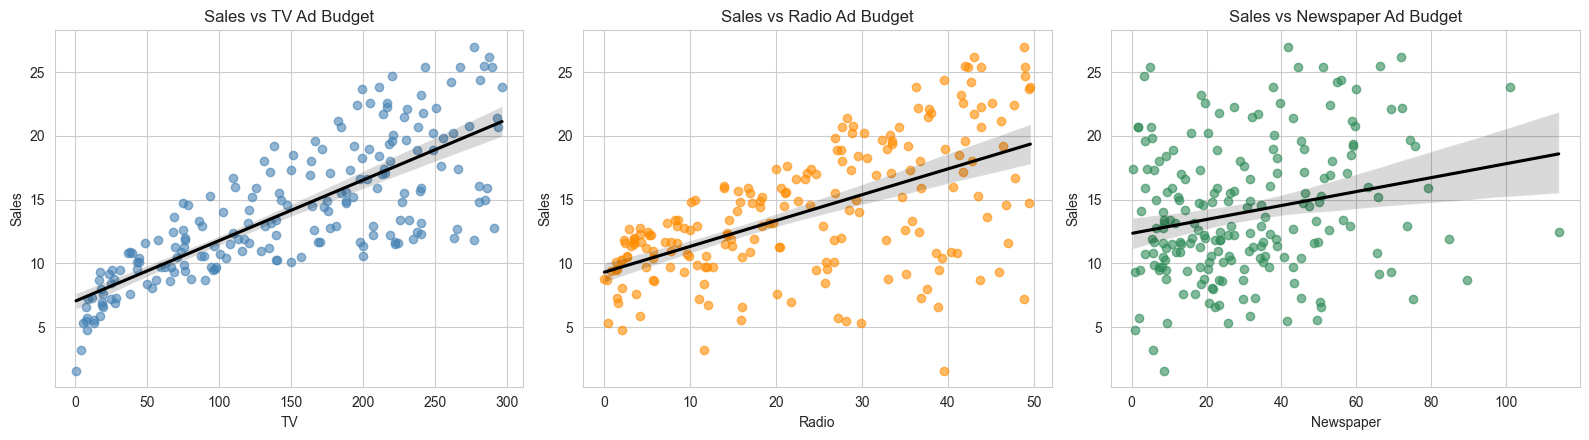

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, channel, color in zip(axes, ["TV", "Radio", "Newspaper"],
                              ["steelblue", "darkorange", "seagreen"]):
    sns.regplot(data=df, x=channel, y="Sales", ax=ax, color=color,
                scatter_kws={"alpha": 0.6}, line_kws={"color": "black"})
    ax.set_title(f"Sales vs {channel} Ad Budget")
plt.tight_layout()
plt.show()

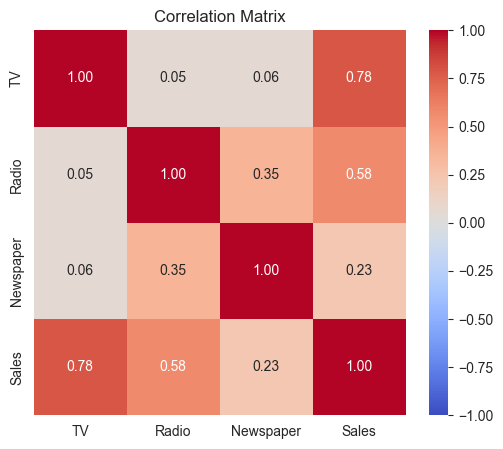

In [24]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

### EDA Observations
- The dataset has 200 rows, 3 predictors and 1 target, with no nulls or duplicates.
- **TV** has the strongest relationship with Sales (correlation about 0.78). The scatter plot is linear.
- **Radio** has a moderate positive relationship, but the points are more spread out.
- **Newspaper** has the weakest relationship (about 0.23). Its scatter plot is almost a cloud.
- Newspaper and Radio are slightly correlated with each other (about 0.35), so
  part of Newspaper's apparent link to sales may come through Radio.

In [25]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", X_train.shape[0], "| Testing samples:", X_test.shape[0])

Training samples: 160 | Testing samples: 40


In [26]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg 2)": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False), LinearRegression()
    ),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(rows).set_index("Model").round(3)
results_df

,MAE,RMSE,R²
Model,,,
Linear Regression,1.461,1.782,0.899
Polynomial Regression (deg 2),0.526,0.643,0.987
Random Forest,0.629,0.757,0.982


In [27]:
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    cv_rows.append({"Model": name, "CV R² Mean": scores.mean(), "CV R² Std": scores.std()})

cv_df = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_df

,CV R² Mean,CV R² Std
Model,,
Linear Regression,0.887,0.040
Polynomial Regression (deg 2),0.984,0.013
Random Forest,0.976,0.009


Best model by cross-validation: Polynomial Regression (deg 2)


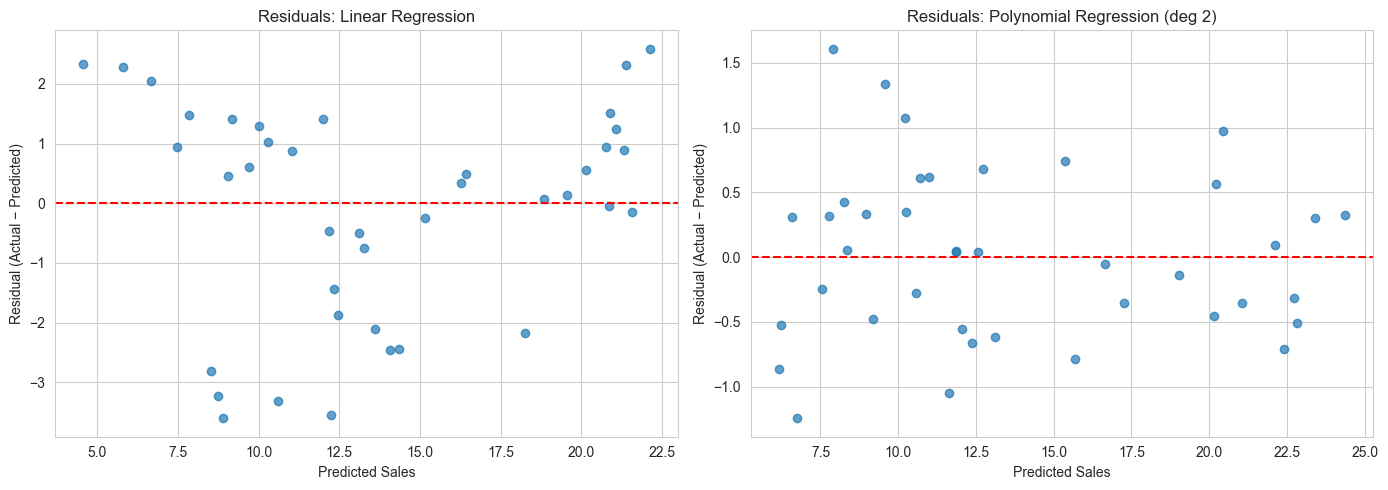

In [28]:
best_name = cv_df["CV R² Mean"].idxmax()
print("Best model by cross-validation:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["Linear Regression", best_name]):
    pred = predictions[name]
    resid = y_test - pred
    ax.scatter(pred, resid, alpha=0.7)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Residuals: {name}")
    ax.set_xlabel("Predicted Sales")
    ax.set_ylabel("Residual (Actual − Predicted)")
plt.tight_layout()
plt.show()

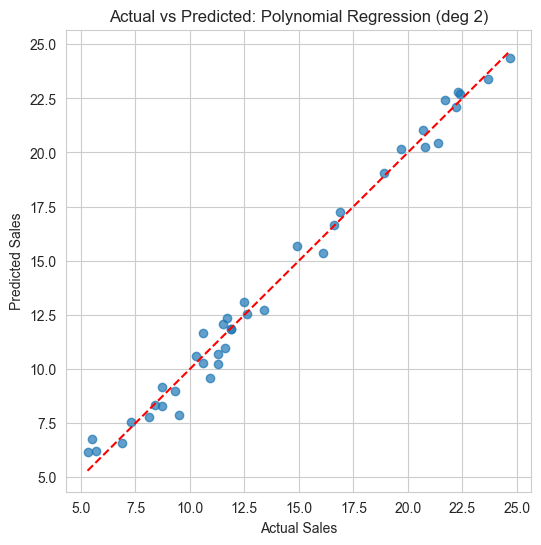

In [29]:
# Actual vs predicted for the best model
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions[best_name], alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted: {best_name}")
plt.show()

In [30]:
lr = models["Linear Regression"]
coef_df = pd.DataFrame({"Channel": X.columns, "Coefficient": lr.coef_}).set_index("Channel").round(4)
print("Intercept:", round(lr.intercept_, 3))
coef_df

Intercept: 2.979


,Coefficient
Channel,
TV,0.0447
Radio,0.1892
Newspaper,0.0028


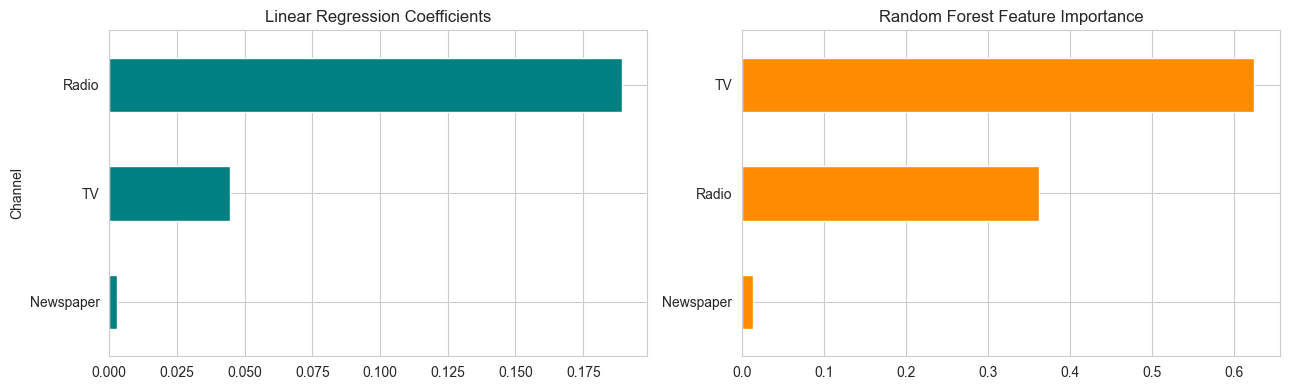

In [31]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
coef_df["Coefficient"].sort_values().plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Linear Regression Coefficients")
importances.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

### Model Evaluation
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 1.461 | 1.782 | 0.899 |
| Polynomial Regression (deg 2) | 0.526 | 0.643 | 0.987 |
| Random Forest | 0.629 | 0.757 | 0.982 |

- The baseline Linear Regression explains about 90% of the variance in sales.
- The more flexible models cut the errors by more than half: Polynomial
  Regression reaches MAE 0.526 and RMSE 0.643, and Random Forest reaches
  MAE 0.629 and RMSE 0.757.
- 5-fold cross-validation (mean R²): Linear = 0.887, Polynomial = 0.984,
  Random Forest = 0.976. Cross-validation confirms the ranking from the test set.

### Residual Analysis
- The **Linear Regression** residuals show a clear U-shaped pattern: the errors are
  positive at low and high predicted sales and negative in the middle, instead of a random scatter.
  This means the linear model misses a non-linear effect, so its errors are systematic.
- The **Polynomial Regression** residuals are smaller (mostly within about ±1.5)
  and more randomly scattered around zero, so its errors look much less systematic.
  The actual vs predicted plot also follows the diagonal line closely.

### Best Model
I select **Polynomial Regression (degree 2)** because it has the highest
cross-validated R² (0.984) and the lowest MAE (0.526) and RMSE (0.643) on the
test set, and its residuals look random. Random Forest is a close second
(R² 0.982 on the test set, 0.976 in cross-validation). The difference between
the two is small, but Polynomial Regression is also simpler and easier to interpret.

### Which Channel Has the Greatest Impact?
- **Linear Regression coefficients:** Radio has the largest effect per extra
  unit of budget (about 0.19 units of sales per 1 unit of Radio spend), TV is
  about 0.045, and Newspaper is close to 0 (0.003).
- **Random Forest importance:** TV is ranked first (about 0.62), then Radio
  (about 0.36), with Newspaper last (about 0.01).
- The two rankings differ because they measure different things. The
  coefficient shows the return per extra dollar, where Radio is strongest. The
  Random Forest importance shows how much each channel contributes to
  predicting sales overall, where TV leads because TV budgets are large and vary a lot.
- Conclusion: TV and Radio are the channels that drive sales, while Newspaper adds
  almost nothing once TV and Radio are accounted for. Newspaper looked
  weakly related to sales in the EDA mostly because it is correlated with Radio.
- The Polynomial model beating the linear one suggests the channels'
  effects are not purely additive (for example, TV and Radio may work better together), though
  I did not test this directly.
- Caveat: this is correlation from observational data, so it doesn't prove that
  spending more on a channel will cause a given increase in sales.

## Conclusion
- Sales can be predicted very accurately from advertising spend (R² about 0.98 with
  Polynomial Regression, versus 0.90 for the linear baseline).
- TV and Radio drive sales; Newspaper contributes almost nothing.
- A business could shift budget away from Newspaper toward Radio and TV, but
  this would need to be tested, since the data is observational.
- Limitation: only 200 observations and three channels, with no other factors such as price or season.